In [2]:
import os

# List all files in the current directory
for file in os.listdir('.'):
    print(file)


.config
train.csv
test.csv
sample_data


In [7]:
from google.colab import files
house_prices = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [8]:
house_prices.keys()

dict_keys(['test.csv', 'train.csv'])

In [3]:
!pip install scikit-learn pandas numpy dtreeviz matplotlib

In [4]:
from scipy.stats import boxcox
from sklearn.preprocessing import StandardScaler
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import GradientBoostingRegressor
import numpy as np

The data is from a kaggle-competition<br>
__Attention__, the test data-set has no target; This is the part you are supposed to upload to kaggle for estimation of your modelling performance;

In [5]:
#house_prices.keys()
train = '/content/' + 'train.csv'
test = '/content/' + 'test.csv'
train = pd.read_csv(train)
test = pd.read_csv(test)

In [6]:

train_ID = train['Id']
test_ID = test['Id']

train.drop('Id', axis = 1, inplace = True)
test.drop('Id', axis = 1, inplace = True)

SalePrice = train['SalePrice']
train.drop('SalePrice', axis=1, inplace = True)

# Now, we want data-leakage
We discussed at length, that train and test-set should be standardized and preprocessed independently; This is only true if we want a fair estimate of our algorithm's performance with new, unseen data.
In the current case we want our training-procedure to be biased towards the test-set, because the test-set performance is what counts in kaggle-competitions.

In [7]:
data = pd.concat((train, test))
data.reset_index(drop = True, inplace = True)
# categorical and numericalvariables:

categorical = [var for var in train.columns if train[var].dtype=='O']
numerical = [var for var in train.columns if train[var].dtype!='O']

# Some preprocessing steps
### we fill missing values with the mean and add an extra variable indicating the missing position: sometimes variables are not 'missing at random' and the fact, that we have a missing value might be meaningful, i.e. there could be information in the NAs. For example, for reasons of discretion, some details are could be missing for very expensive properties.

In [8]:
data[categorical] = data[categorical].fillna('None')


## next, we substitute missing values with the mean of the variable and form new variables
## indicating the missing values. Sometimes data is not missing at random and the fact that
## data is missing might contain valuable information
variables_na = []
for val in numerical:
    data[val + '_na'] = pd.isnull(data[val])
    variables_na.append(val + '_na')
    data[val] = data[val].fillna(data[val].mean())



<ipython-input-8-ae64a599a911>:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[val + '_na'] = pd.isnull(data[val])
<ipython-input-8-ae64a599a911>:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[val + '_na'] = pd.isnull(data[val])
<ipython-input-8-ae64a599a911>:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfra

### we transform the continuous variables to be more normally distributed
[box-cox transform in short](https://www.statisticshowto.com/box-cox-transformation/#:~:text=A%20Box%20Cox%20transformation%20is,a%20broader%20number%20of%20tests.)

In [9]:
## box-cox transform is variance stabilizing. It is meant to make
## the variable more normaly distributed
box_cox = []
new_columns = {}  # Dictionary to store new columns

for val in numerical:
  new_vals, lamb = boxcox(data[val] + 1)
  if np.abs(lamb) < 8:
    new_columns[val + '_box_cox'] = new_vals
    box_cox.append(val)

data = pd.concat([data, pd.DataFrame(new_columns)], axis=1)

### we demonstrate the effect of the box-cox transform

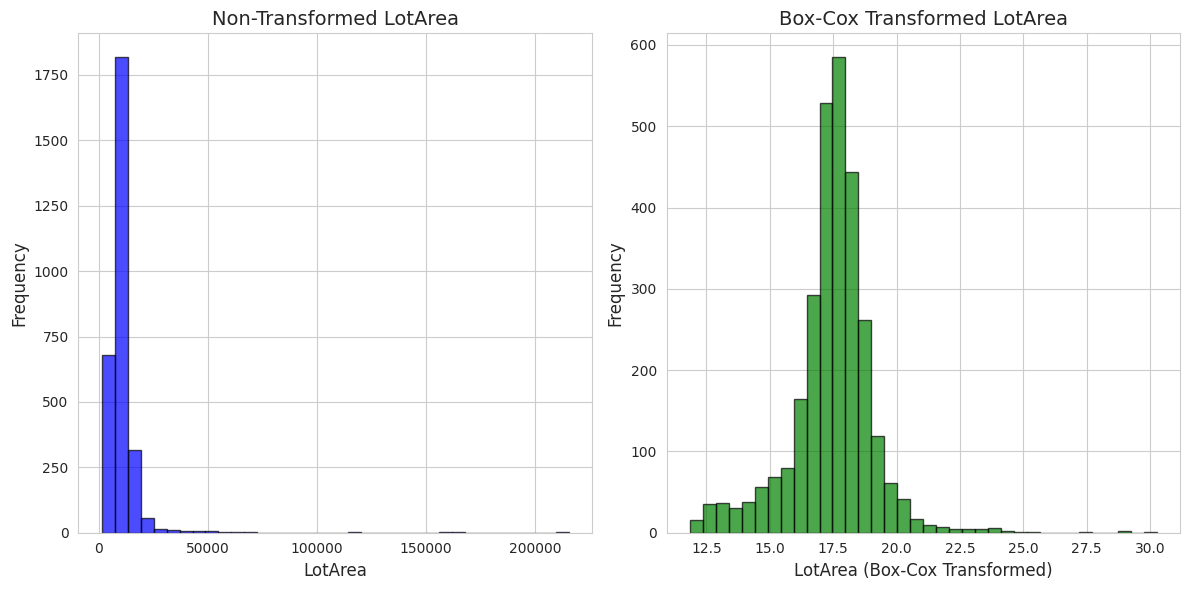

In [10]:
from matplotlib import pyplot as plt
import seaborn as sns  # For better styling
import numpy as np

# Apply Box-Cox transformation
data['LotArea_box_cox'], _ = boxcox(data['LotArea'] + 1)  # Adding 1 to avoid negative values

# Set up the plot
plt.figure(figsize=(12, 6))  # Larger figure size
sns.set_style("whitegrid")  # Use a clean grid background

# Plot 1: Non-transformed variable
ax1 = plt.subplot(1, 2, 1)
ax1.hist(data['LotArea'], bins=int(180/5), color='blue', edgecolor='black', alpha=0.7)
ax1.set_title('Non-Transformed LotArea', fontsize=14)
ax1.set_xlabel('LotArea', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)

# Plot 2: Transformed variable
ax2 = plt.subplot(1, 2, 2)
ax2.hist(data['LotArea_box_cox'], bins=int(180/5), color='green', edgecolor='black', alpha=0.7)
ax2.set_title('Box-Cox Transformed LotArea', fontsize=14)
ax2.set_xlabel('LotArea (Box-Cox Transformed)', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)

# Adjust layout and display
plt.tight_layout()
plt.show()

### we encode categorical data as dummy-variables (aka one-hot encoding)

In [11]:
# as already announced, categorical data is one-hot encoded (dummy-coded)

data_base = pd.get_dummies(data[[col for col in data.columns if col not in variables_na]])
data_na = pd.get_dummies(data[variables_na])

# we have to cast every variable's data type to float32 for our next 'trick'
data_base = data_base.astype(np.float32)
data_na = data_na.astype(np.float32)
data_numerical = data[numerical]

data = pd.concat([data_base, data_na], axis = 1)

### we compute the feature importance in order to get the most relevant variable
With this trick we identify the most relevant variables. Like this, we are adding interaction-terms only for the most relevant variables.

In [12]:
# the number of variables is quiet high. We want to add interaction terms for the most important
# variables. Therefore, we want to compute some variable-importance measure. This is
# done by the help of gradient boosted trees:
gbm = GradientBoostingRegressor(n_estimators = 32, max_depth = 4)
gbm.fit(data.iloc[0:len(train_ID)], SalePrice)

GradientBoostingRegressor(max_depth=4, n_estimators=32)

In [19]:
from sklearn.inspection import permutation_importance

# we sort the variables (indizes) by variable importance
indizes = np.argsort(gbm.feature_importances_)
result = permutation_importance(gbm, data.iloc[0:len(train_ID)], SalePrice, n_repeats=10,
                                random_state=42, n_jobs=2)
sorted_idx = result.importances_mean.argsort()

<ipython-input-20-2bc42f2e1c90>:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(result.importances[sorted_idx[-15:]].T,


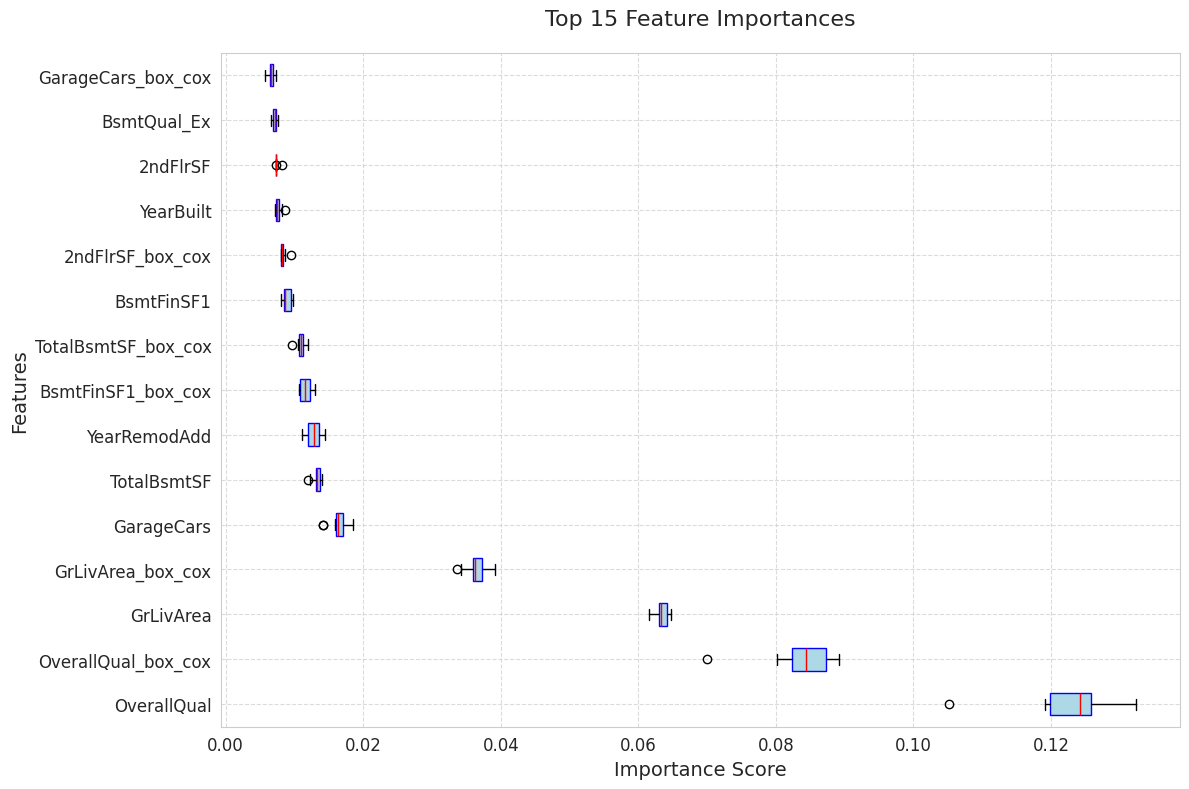

In [20]:
from matplotlib import pyplot as plt
import seaborn as sns  # For better styling

# Set up the plot
fig, ax = plt.subplots(figsize=(12, 8))  # Larger figure size
sns.set_style("whitegrid")  # Use a clean grid background

# Plot the feature importances
ax.boxplot(result.importances[sorted_idx[-15:]].T,
           vert=False, labels=np.array(data.columns)[sorted_idx[-15:]],
           patch_artist=True,  # Fill boxes with color
           boxprops=dict(facecolor='lightblue', color='blue'),  # Box colors
           medianprops=dict(color='red'))  # Median line color

# Add title and labels
ax.set_title('Top 15 Feature Importances', fontsize=16, pad=20)
ax.set_xlabel('Importance Score', fontsize=14)
ax.set_ylabel('Features', fontsize=14)

# Adjust font sizes
ax.tick_params(axis='both', which='major', labelsize=12)

# Invert y-axis to show the most important feature at the top
ax.invert_yaxis()

# Add grid lines for better readability
ax.grid(True, linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

## for the most important features we compute the interactions
### in the first step we include only the most important 15 variables to form interaction-terms

In [21]:
# import a tool for getting all possible n over 2 combinations of these variables
from itertools import combinations
# and add the interactions
interactions = []
new_cols = {}
for comb in list(combinations(data.columns[sorted_idx[-15:]], 2)):
  new_cols[comb[0] + '_x_' + comb[1]] = data[comb[0]] * data[comb[1]]
  interactions.append(comb[0] + '_x_' + comb[1])

data = pd.concat([data, pd.DataFrame(new_cols)], axis=1)

data_interactions = data[interactions]

### in the second step we include even 55 variables to form interactions

In [22]:
interactions2 = []
new_columns = {}
for comb in list(combinations(data.columns[sorted_idx[-55:]], 2)):
    new_columns[comb[0] + '_x_' + comb[1]] = data[comb[0]] * data[comb[1]]
    interactions2.append(comb[0] + '_x_' + comb[1])

data = pd.concat([data, pd.DataFrame(new_columns)], axis=1)
data_interactions2 = data[interactions2]

In [23]:
## 1.
# now, we have different data sets
# the base set with missing values imputed by the mean and no other feature engineering
# box-cox transformed variables are removen
base = data_base[[col for col in data_base.columns if not col.endswith('_box_cox')]]
## 2.
# box_cox is admitted; original variables removed
with_box_cox = data_base[[col for col in data_base.columns if not col in box_cox]]
## 3.
# variables indicating formerly missing values are included
with_na = pd.concat([with_box_cox, data_na], axis = 1)
## 4.
# all interaction terms of the 55 most important variables are added
with_interactions = pd.concat([with_na, data_interactions], axis = 1)
## 5.
## we exagerate the number of interactions
with_interactions2 = pd.concat([with_na, data_interactions2], axis=1)
## the target variable is log-transformed
y = np.log1p(SalePrice)

## since we want to try elasticnet, we have to find the optimal parameter for
# lambda (amount of regularization) and for alpha (ratio of lasso and ridge mixing)
lamb = 10**(np.linspace(-1, 0.2, 15))
# ratio
ratio = np.linspace(0, 1, 10)

### excurs: parameter sampling on a logarithmic scale<br>
sample some of the parameters on a logrithmic scale:
https://www.coursera.org/lecture/deep-neural-network/using-an-appropriate-scale-to-pick-hyperparameters-3rdqN

$b^y = x; \; y = log_b(x)$


In [24]:
np.linspace(0.0001, 0.1, 5) # 5 equally spaced values from 0.0001 to 0.1

array([0.0001  , 0.025075, 0.05005 , 0.075025, 0.1     ])

As you can see, there is no value between 0.0001 and 0.001 and no value between 0.001 and 0.01. But there are three values between 0.01 and 0.1<br>
Now, compare to this solution:

In [25]:
10**np.linspace(-4, -1, 5)

array([0.0001    , 0.00056234, 0.00316228, 0.01778279, 0.1       ])

### we transform the SalePrice (y) as well

In [26]:
# the function np.log1p is well defined at 0
display(np.log(0), np.log(1), np.log(2),
        np.log1p(1), np.log1p(0))

<ipython-input-26-9f894fc76710>:2: RuntimeWarning: divide by zero encountered in log
  display(np.log(0), np.log(1), np.log(2),


-inf

0.0

0.6931471805599453

0.6931471805599453

0.0

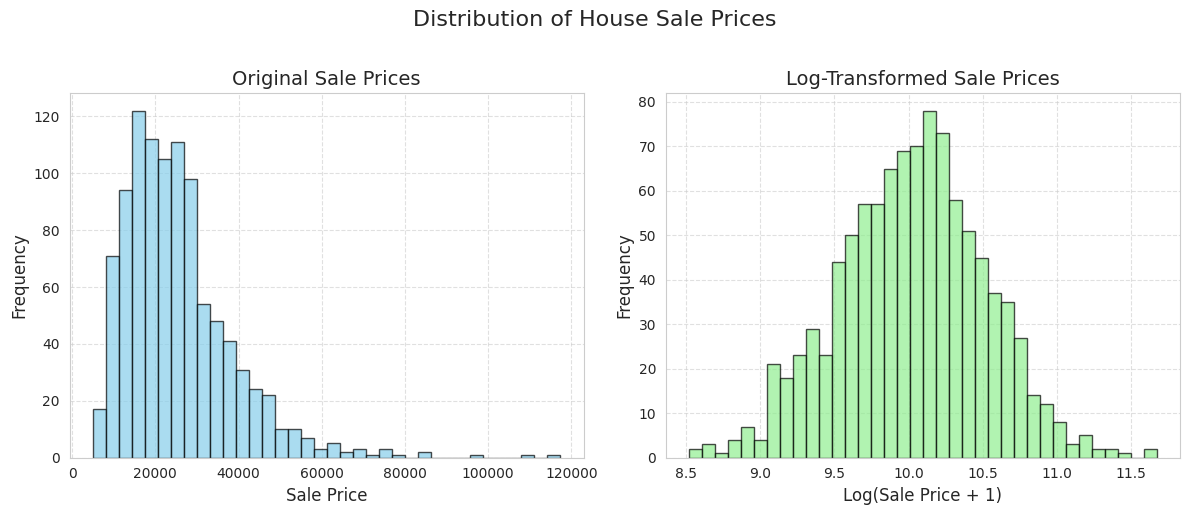

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming SalePrice is your data
# Example data (replace with your actual data)
SalePrice = np.random.lognormal(mean=10, sigma=0.5, size=1000)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Non-transformed variable
axes[0].hist(SalePrice, bins=int(180/5), color='skyblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Original Sale Prices', fontsize=14)
axes[0].set_xlabel('Sale Price', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Log-transformed variable
axes[1].hist(np.log1p(SalePrice), bins=int(180/5), color='lightgreen', edgecolor='black', alpha=0.7)
axes[1].set_title('Log-Transformed Sale Prices', fontsize=14)
axes[1].set_xlabel('Log(Sale Price + 1)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

# Add a super title for the entire figure
fig.suptitle('Distribution of House Sale Prices', fontsize=16, y=1.02)

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

### polynomial features
We can even do more. The function `sklearn.preprocessing.PolynomialFeatures`generates all polynomials of a certain degree; for example, if the degree = 2 and there are two variables (a and b) it generates all $a, b, a\cdot b, a^2\,\, \text{and}\,\,  b^2$ terms.

In [28]:
from sklearn.preprocessing import PolynomialFeatures
pl = PolynomialFeatures(3, interaction_only = False, include_bias=False)

In [25]:
polies = pl.fit_transform(data[data.columns[sorted_idx[-15:]]])
X_polynomial = pd.concat([with_na, pd.DataFrame(polies,columns = [str(i) for i in range(polies.shape[1])])], axis=1)

In [26]:
error = []
best_parameters = []
# we iterate over list of data-sets
# X_polynomial,
for d in [base, with_box_cox, with_na, with_interactions, X_polynomial,  with_interactions2]:
# for d in [with_interactions, X_polynomial]:
    # scale variables
    scaler = StandardScaler()
    scaler.fit(d[:len(train_ID)]) #  fit  the scale

    X_train = scaler.transform(d[:len(train_ID)])
    X_test = scaler.transform(d[len(train_ID):])

    # the function cross_val_score computes the model passed to it for cv=5-fold
    # cross validation; we compute the mean over the 5 folds
    get_results = [(la, r, np.mean(np.sqrt(-cross_val_score(ElasticNet(alpha = la,
                                                            l1_ratio = r),
            X_train, y , scoring = 'neg_mean_squared_error',
            cv = 5, n_jobs = -1))))
                for la in lamb for r in ratio]

    # the least error is extracted
    least_error = np.min([i[2] for i in get_results])
    error.append(least_error)
    # the parameters belonging to the best result
    parameters = [i[0:2] for i in get_results if i[2] == least_error]
    best_parameters.append(parameters)
    print(f'least error is: {least_error}, best parameters are: {parameters}')


least error is: 0.13822807638787132, best parameters are: [(0.3981071705534972, 0.0)]
least error is: 0.1306575817225515, best parameters are: [(0.1, 0.1111111111111111)]
least error is: 0.13065758750886855, best parameters are: [(0.1, 0.1111111111111111)]
least error is: 0.12917252902971307, best parameters are: [(0.14839817889675655, 0.0)]
least error is: 0.12118987675193334, best parameters are: [(0.5907837911587945, 0.0)]
least error is: 0.11655952288252844, best parameters are: [(0.5907837911587945, 0.0)]


In [27]:
best_parameters

[[(0.3981071705534972, 0.0)],
 [(0.1, 0.1111111111111111)],
 [(0.1, 0.1111111111111111)],
 [(0.14839817889675655, 0.0)],
 [(0.5907837911587945, 0.0)],
 [(0.5907837911587945, 0.0)]]

In [29]:
X_polynomial[:len(train_ID)].shape

(1460, 1161)

In [ ]:
# more variables than training examples, but best cross-validation result:
with_interactions2[:len(train_ID)].shape

(1460, 1936)

We conclude:
1. box-cox transform helps: Regression is based on the normal distribution and having variables more normally distributed is a good thing.
2. NAs seem to be there at random. There is no benefit from marking the positions of NAs before imputing the values.
3. Interactions among the 15 most important variables helps
4. adding polynomials of the 15 most important variables helps even more
5. adding interactions among the 55 most important variables is the best result


One additional note: By including the interaction2 terms, we have __more variables (1936) than observations (1460)__ in the training set. This situation is not admissable in classical statistics. For machine learning algorithms with regularization and/or iterative optimization, it does not mean any problem.<br>
<br>
## Now, we are doing all the processing steps within a pipeline
this can prevent overfitting as we will see later.<br>

We are not adding interaction-terms here;

One-hot encoding and adding variables for missing values is not critical: no statistics are fitted<br>

we load the data (only train) once again:

In [13]:
train = '/content/' + 'train.csv'

train = pd.read_csv(train)

train_ID = train['Id']
train.drop('Id', axis = 1, inplace = True)
SalePrice = train['SalePrice']
train.drop('SalePrice', axis=1, inplace = True)
categorical = [var for var in train.columns if train[var].dtype=='O']
numerical = [var for var in train.columns if train[var].dtype!='O']

Next we add an indicator variable for every missing value: no statistics are fitted:

In [14]:
train[categorical] = train[categorical].fillna('None')
for val in numerical:
    train[val + '_na'] = pd.isnull(train[val])

the follwing statistics however, depend on the data:<br>
- filling NAs with mean-values
- box-cox transform of variable
- fitting the model

In [ ]:
import sys
import os
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(missing_values=np.nan, strategy='mean')),
    ('scaler', PowerTransformer(method='box-cox'))])

categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical),
        ('cat', categorical_transformer, categorical),
        ])

clf = GridSearchCV(
        make_pipeline(
            preprocessor,
            ElasticNet()
            ),
            param_grid={'elasticnet__alpha': 10**(np.linspace(-1, 0.2, 5)),
                        'elasticnet__l1_ratio': np.linspace(0, 1, 6)},
         cv=5, refit=False, scoring = 'neg_mean_squared_error'
)


In [25]:
train[numerical] += 1
clf.fit(train, np.log1p(SalePrice))

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.140e+00, tolerance: 1.891e-03 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.050e+00, tolerance: 1.800e-03 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_mode

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          PowerTransformer(method='box-cox')),
                                                                                         ('poly',
                                                                                          PolynomialFeatures(degree=3,
                                                                                                             include_bias=False))]),
                                                                         ['MSSubClass',
                                                                          'LotFrontage',
                                                                          'LotArea',
                                                                          'OverallQual',
                                                                          'OverallCond',
                                                                          'YearBuilt',
                                                                          'YearRemodAdd',
                                                                          'Mas...
                                                                          'BsmtCond',
                                                                          'BsmtExposure',
                                                                          'BsmtFinType1',
                                                                          'BsmtFinType2',
                                                                          'Heating',
                                                                          'HeatingQC',
                                                                          'CentralAir',
                                                                          'Electrical', ...])])),
                                       ('elasticnet',
                                        ElasticNet(max_iter=2000, tol=1e-05))]),
             param_grid={'elasticnet__alpha': array([0.1       , 0.19952623, 0.39810717, 0.79432823, 1.58489319]),
                         'elasticnet__l1_ratio': array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])},
             refit=False, scoring='neg_mean_squared_error')

In [26]:
display(clf.best_params_, np.sqrt(-clf.best_score_))
# clf.cv_results_.keys()

{'elasticnet__alpha': 0.1, 'elasticnet__l1_ratio': 0.2}

0.15656102605649186

In [ ]:
clf.cv_results_.keys()

dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_elasticnet__alpha', 'param_elasticnet__l1_ratio', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score'])

In [ ]:
np.sqrt(-clf.cv_results_['mean_test_score'])

array([0.13237803, 0.1493028 , 0.16540801, 0.18267359, 0.19985306,
       0.21528227, 0.13500173, 0.168074  , 0.20169271, 0.23435203,
       0.26753428, 0.299449  , 0.13929797, 0.2067523 , 0.27600369,
       0.33904176, 0.39445307, 0.39954338, 0.14674367, 0.28669422,
       0.39540082, 0.39954338, 0.39954338, 0.39954338, 0.16027503,
       0.39657224, 0.39954338, 0.39954338, 0.39954338, 0.39954338])

#TASK:
can you add the Polynomial calculation to the pipeline

# Reminder
We found the best parameters via extensive search over the whole data-set. As we have discussed, theoretically nested-cross-validation (aka double-cross-validation) would have been the better choice. However, it would also be computationally more expensive.